# BIOT 6900 · Module 6, Part 3 — Extension: the same workflow on a PDAC score

**Why this notebook exists.** The graded Part 3 run uses the Canvas data pack (Alzheimer's panel, PGS000334). My Part I disease is **pancreatic ductal adenocarcinoma (PDAC)**, and no PDAC variant is on that panel. Here I apply a published PDAC score to the **same 2,336 1000 Genomes people**.

- **Score:** PGS000725 "PRS_Pancreas" (Jia G et al., *JNCI Cancer Spectr* 2020): 22 genome-wide-significant variants, hg19, beta weights, GWAS and evaluation 100% European.
- **Genotypes:** retrieved from 1000 Genomes phase 3 via the Ensembl REST API with `build_pdac_data.py`. ALT = the non-REF allele actually observed in 1000 Genomes. Strand was checked by comparing EUR effect-allele frequency against the PGS-reported frequency (all within ±0.035).
- **Scope:** real-data parts only (harmonization, PRS distribution shift, single-cutoff fractions, allele frequencies). **No AUC or calibration**: there is no PDAC phenotype for 1000 Genomes, and simulating one from this same score would build the answer in.


## 0. Setup

In [1]:
import os, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

NU_RED, NU_COOL, NU_GREY = "#C8102E", "#1E2028", "#6E7178"
POP_COLORS = {"EUR":"#1E2028","AFR":"#C8102E","EAS":"#6E7178","SAS":"#A4804A","AMR":"#9AA0A6"}
rng = np.random.default_rng(6900)

USE_DEMO = False     # <-- prototyping only. MUST be False for your graded submission.

## 1. Load PDAC data (data_pdac/)

In [2]:
BASES = np.array(list("ACGT"))
def _make_demo_cohort(seed=6900):
    r = np.random.default_rng(seed)
    pops = {"EUR":(600,0.92,0.05,0.14),"AFR":(600,0.40,0.15,0.22),"EAS":(500,0.58,0.12,0.09),
            "SAS":(500,0.66,0.09,0.09),"AMR":(500,0.55,0.07,0.11)}   # n, tag-rho, drift, APOE freq
    M = 80
    b = r.normal(0, 0.15, M); b[0] = 1.3
    w_true = b * 0.92
    base = r.uniform(0.15, 0.5, M)
    Gt, Gc, anc, ages = [], [], [], []
    for pop,(n,rho,drift,apoe) in pops.items():
        f = np.clip(base + r.normal(0,drift,M), 0.03, 0.97); f[0] = apoe; thr = norm.ppf(f)
        gc = np.zeros((n,M)); gt = np.zeros((n,M))
        for _ in range(2):
            L = r.normal(size=(n,M)); Z = r.normal(size=(n,M))
            gc += (L<thr); gt += ((rho*L + np.sqrt(1-rho**2)*Z) < thr)
        Gt.append(gt); Gc.append(gc); anc += [pop]*n; ages.append(r.normal(60,8,n))
    Gt = np.vstack(Gt); Gc = np.vstack(Gc); anc = np.array(anc); age = np.concatenate(ages)
    lin = Gc @ b + 0.03*(age-60); b0 = np.log(0.30/0.70) - lin.mean()
    y = (r.uniform(size=len(lin)) < 1/(1+np.exp(-(b0+lin)))).astype(int)
    variants = [f"rs_tag_{i:03d}" for i in range(M)]
    # real nucleotides: pick ref != alt; dosages count ALT
    ref = r.choice(BASES, M); alt = np.array([r.choice(BASES[BASES!=ref[i]]) for i in range(M)])
    geno = pd.DataFrame(Gt, columns=variants)
    vtab = pd.DataFrame({"variant":variants, "ref":ref, "alt":alt})
    # 25% of rows report the REF allele as effect allele, with the weight's sign reversed
    report_ref = r.random(M) < 0.25
    eff = np.where(report_ref, ref, alt); oth = np.where(report_ref, alt, ref)
    wrep = np.where(report_ref, -w_true, w_true)
    score = pd.DataFrame({"variant":variants, "effect_allele":eff, "other_allele":oth, "weight":wrep})
    meta  = pd.DataFrame({"ancestry":anc, "age":age, "phenotype":y})
    return geno, vtab, score, meta

REAL_FILES = ["genotypes.csv","variants.csv","score.csv","meta.csv"]
def _sha8(path):
    h = hashlib.sha256(open(path,"rb").read()).hexdigest()[:8]
    return h

def load_data(path="data"):
    present = [f for f in REAL_FILES if os.path.exists(os.path.join(path,f))]
    if not USE_DEMO:
        missing = [f for f in REAL_FILES if f not in present]
        if missing:
            raise FileNotFoundError(
                "GRADED RUN requires all four files in ./%s/ . Missing: %s .  "
                "Set USE_DEMO=True ONLY to prototype on synthetic data; it must be False for submission."
                % (path, ", ".join(missing)))
        geno=pd.read_csv(os.path.join(path,"genotypes.csv"))
        vtab=pd.read_csv(os.path.join(path,"variants.csv"))
        score=pd.read_csv(os.path.join(path,"score.csv"))
        meta=pd.read_csv(os.path.join(path,"meta.csv"))
        info={"source":"REAL","hashes":{f:_sha8(os.path.join(path,f)) for f in REAL_FILES}}
        print("="*64); print("  RUNNING ON REAL DATA"); print("="*64)
    else:
        print("="*64); print("  USE_DEMO=True  ->  SYNTHETIC demo cohort  (NOT FOR GRADING)"); print("="*64)
        geno,vtab,score,meta=_make_demo_cohort(); info={"source":"DEMO","hashes":None}
    return geno, vtab, score, meta, info

geno, variants, score, meta, info = load_data("data_pdac")

  RUNNING ON REAL DATA


## 2. Proof of data

In [3]:
print("source      :", info["source"])
print("people      :", len(meta))
print("score size  :", len(score), "variants")
print("by ancestry :", dict(meta["ancestry"].value_counts()))
if info["source"] == "REAL":
    for f,h in info["hashes"].items():
        print(f"  {f}: sha256 {h}")
else:
    print("  DEMO cohort - not acceptable for your graded submission")

source      : REAL
people      : 2336
score size  : 22 variants
by ancestry : {'AFR': np.int64(500), 'EAS': np.int64(500), 'EUR': np.int64(500), 'SAS': np.int64(489), 'AMR': np.int64(347)}
  genotypes.csv: sha256 c4309c10
  variants.csv: sha256 4f9d8781
  score.csv: sha256 9135fb69
  meta.csv: sha256 a9ebe2fb


## 3.1 Harmonize alleles

In [4]:
shared = [v for v in score["variant"] if v in geno.columns]
G = geno[shared].to_numpy(dtype=float).copy()
s = score.set_index("variant").loc[shared]
v = variants.set_index("variant").loc[shared]
eff = s["effect_allele"].to_numpy()
ref = v["ref"].to_numpy(); alt = v["alt"].to_numpy()
w = s["weight"].to_numpy()

# uppercase + strip first so case/whitespace differences are not counted as mismatches
eff = np.char.upper(np.char.strip(eff.astype(str)))
ref = np.char.upper(np.char.strip(ref.astype(str)))
alt = np.char.upper(np.char.strip(alt.astype(str)))

keep = eff == alt                      # effect allele == ALT -> dosage already counts it
flip = eff == ref                      # effect allele == REF -> count it with 2 - dosage
drop = ~(keep | flip)                  # neither (strand / build mismatch)

G[:, flip] = 2 - G[:, flip]            # flip first, while masks still line up with G's columns
G = G[:, ~drop]; w = w[~drop]          # then remove dropped variants from dosages and weights
used_variants = [x for x, d in zip(shared, drop) if not d]

n_absent = len(score) - len(shared)    # score variants not in the genotype panel at all
print(f"used {int((keep|flip).sum())}  flipped {int(flip.sum())}  dropped {int(drop.sum())}")
print(f"score variants: {len(score)}  |  found in panel: {len(shared)}  |  not in panel: {n_absent}")
if drop.any(): print("dropped (allele mismatch):", [x for x, d in zip(shared, drop) if d])


used 21  flipped 12  dropped 0
score variants: 22  |  found in panel: 21  |  not in panel: 1


## 3.2 Compute the PRS

In [5]:
# PRS = dosages times weights, summed per person
if "sample_id" in geno.columns and "sample_id" in meta.columns:   # rows must be the same people, same order
    assert (geno["sample_id"].to_numpy() == meta["sample_id"].to_numpy()).all(), "geno/meta rows out of order"
prs = G @ w
prs_z = (prs - prs.mean()) / prs.std()
meta["prs"] = prs_z
print("PRS computed for", len(prs_z), "people")


PRS computed for 2336 people


## 3.3 Distribution shift and a single cutoff

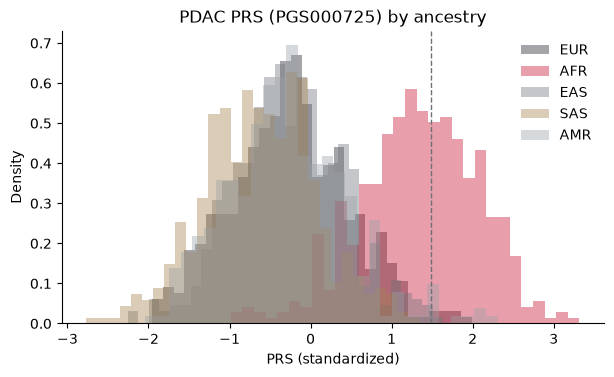

whole-cohort top-10% cutoff (standardized PRS): 1.483
            n  mean PRS  % above top-10% cutoff
ancestry                                       
EUR       500     -0.26                     1.2
AFR       500      1.33                    43.4
EAS       500     -0.26                     0.2
SAS       489     -0.62                     0.0
AMR       347     -0.30                     2.9


In [6]:
os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(7,3.8))
for pop, c in POP_COLORS.items():
    sub = meta.loc[meta.ancestry==pop, "prs"]
    ax.hist(sub, bins=30, density=True, alpha=0.4, color=c, label=pop)
ax.set_title("PDAC PRS (PGS000725) by ancestry"); ax.set_xlabel("PRS (standardized)"); ax.set_ylabel("Density"); ax.legend(frameon=False)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
cutoff = np.quantile(meta["prs"], 0.90)
ax.axvline(cutoff, color=NU_GREY, ls="--", lw=1)
fig.savefig("figures/PDAC_prs_distribution_by_ancestry.png", dpi=200, bbox_inches="tight")
plt.show()

# for each ancestry: mean PRS and % of the group above the whole-cohort top-10% cutoff
print(f"whole-cohort top-10% cutoff (standardized PRS): {cutoff:.3f}")
summary = pd.DataFrame({
    "n":                       meta.groupby("ancestry")["prs"].size(),
    "mean PRS":                meta.groupby("ancestry")["prs"].mean().round(2),
    "% above top-10% cutoff":  (100*(meta["prs"] > cutoff).groupby(meta["ancestry"]).mean()).round(1),
}).loc[list(POP_COLORS)]
print(summary)


### 3.3b Effect-allele frequency by ancestry *(extra, supports interpretation Q1)*

The PRS shift in 3.3 comes from real allele-frequency differences. This table shows, for each score variant, how often the effect allele appears in each group.


In [7]:
Gd = G / 2                                                    # effect-allele frequency per person/variant
af = pd.DataFrame(Gd, columns=used_variants).groupby(meta["ancestry"].to_numpy()).mean().T[list(POP_COLORS)]
af.insert(0, "weight", w)
af["max-min"] = af[list(POP_COLORS)].max(axis=1) - af[list(POP_COLORS)].min(axis=1)
print(af.round(3).sort_values("max-min", ascending=False).to_string())


            weight    EUR    AFR    EAS    SAS    AMR  max-min
rs2816938    0.191  0.240  0.807  0.056  0.093  0.205    0.751
rs13303010   0.231  0.099  0.829  0.291  0.125  0.303    0.730
rs9543325    0.215  0.389  0.946  0.431  0.339  0.431    0.607
rs1561927    0.117  0.753  0.405  0.977  0.718  0.772    0.572
rs2941471    0.117  0.575  0.919  0.363  0.500  0.434    0.556
rs3790844    0.211  0.762  0.890  0.349  0.531  0.597    0.541
rs9581943    0.140  0.431  0.077  0.386  0.545  0.267    0.468
rs2736098    0.174  0.765  0.927  0.628  0.497  0.797    0.430
rs401681     0.174  0.442  0.597  0.319  0.195  0.434    0.402
rs9854771    0.105  0.611  0.758  0.856  0.748  0.536    0.320
rs17688601   0.128  0.747  0.967  0.954  0.650  0.774    0.317
rs4795218    0.128  0.760  0.971  0.670  0.824  0.807    0.301
rs1486134    0.122  0.265  0.148  0.427  0.269  0.281    0.279
rs7190458    0.307  0.046  0.282  0.032  0.007  0.065    0.275
rs73328514   0.163  0.896  0.741  0.997  0.912  0.909  